# `tl.spatial_gene_modules(correlation='moran_bv')` vs `esda.Moran_BV`

`spatial_gene_modules` never exposes the internal gene x gene spatial correlation matrix it builds, so this notebook calls the private `_spatial_corr_matrix` helper directly - the actual code path, not a hand-copy that could drift out of sync.

Two conventions matter for the comparison. First, astrolabe standardizes with `ddof=0` while `esda.Moran_BV` uses `ddof=1`; these cancel out algebraically, so it's not a real difference. Second, bivariate Moran's I with a row-standardized W is genuinely **not symmetric** (`I(x,y) != I(y,x)`), so astrolabe reports `(I(i,j) + I(j,i)) / 2` for every off-diagonal pair and hardcodes the diagonal to 1.0. The comparison below symmetrizes esda's raw output the same way before comparing, rather than expecting `esda.Moran_BV(x, y)` alone to match.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import time
import numpy as np
import scipy.sparse as sp
import astrolabe as ab
import esda

from astrolabe.tl._gene_modules import _spatial_corr_matrix, _row_normalize


INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


## Dataset

`ab.datasets.xenium_tiny()`, restricted to a small (~18 gene) subset — a
genome-wide `esda.Moran_BV` loop over every gene pair (`O(n_genes^2)`
separate weight-graph evaluations) is intractable for a benchmark notebook;
the point here is validating the formula, not genome-wide throughput.


In [2]:
mdata = ab.datasets.xenium_tiny()
ab.pipeline.filter_xenium(mdata)
ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.tl.spatial_neighbors(mdata)

adata = mdata["xenium"]
gene_subset = list(adata.var_names[:18])
adata


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\esda\.astrolabe_cache\datasets\xenium_tiny\outs


C:\Users\Austin\PycharmProjects\astrolabe\astrolabe\io\_xenium.py:870: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  adata.obsm[obsm_key] = ak.Array(
INFO:astrolabe.io._xenium:Loaded 358 cells × 520 features (115 control probes)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\benchmarks\esda\.astrolabe_cache\datasets\xenium_tiny\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 20999 transcript detections


INFO:astrolabe.pipeline:filter_xenium: 358 cells × 520 genes


...

INFO:astrolabe.pp._qc:  synced uns['transcripts']: 20163 -> 20160 rows (dropped filtered-out genes)


INFO:astrolabe.pipeline:  [remove_controls] 370 → 255 genes  (removed 115, 31.1%)


INFO:astrolabe.pipeline:filter_xenium: done — 328 cells × 255 genes


INFO:astrolabe.tl._graph:spatial_neighbors: 328 cells, 5670 edges (mean degree 17.3) [generic]


AnnData object with n_obs × n_vars = 328 × 255
    obs: 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'nucleus_count', 'unassigned_codeword_total', 'deprecated_codeword_total', 'genomic_control_probe_total', 'negative_control_codeword_total', 'negative_control_probe_total', 'any_negative_control_probe_total', 'n_unassigned_codewords', 'n_deprecated_codewords', 'n_genomic_control_probes', 'n_negative_control_codewords', 'n_negative_control_probes', 'n_any_negative_control_probes', 'pct_unassigned_codewords', 'pct_deprecated_codewords', 'pct_genomic_control_probes', 'pct_negative_control_codewords', 'pct_negative_control_probes', 'pct_any_negative_control_probes', 'pct_counts_control', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'nucleus_to_cell_area_ratio', 'has_nucleus', 'total_counts_norm'
    var: 

## Astrolabe: the real `_spatial_corr_matrix` code path

Replicated exactly as `spatial_gene_modules` itself does it: subset to the
gene panel, standardize with `ddof=0`, row-normalize the spatial graph, then
call the private helper.


In [3]:
gene_idx = np.array([adata.var_names.get_loc(g) for g in gene_subset])
X = adata.X
if sp.issparse(X):
    X = X.toarray()
X = np.asarray(X, dtype=np.float64)[:, gene_idx]

mu = X.mean(axis=0)
sigma = X.std(axis=0)  # ddof=0, matches spatial_gene_modules exactly
sigma[sigma == 0] = 1.0
Z = (X - mu) / sigma

conn_key = "spatial_neighbors_connectivities"
W_norm = _row_normalize(adata.obsp[conn_key])

_t0 = time.perf_counter()
corr_astro = _spatial_corr_matrix(Z, W_norm, "moran_bv")
t_astro_s = time.perf_counter() - _t0
print(f"astrolabe runtime: {t_astro_s:.4f}s")
corr_astro.shape


astrolabe runtime: 0.0003s


(18, 18)

## Reference: `esda.Moran_BV` looped over every ordered gene pair

`esda.Moran_BV` takes raw (not pre-standardized) expression and standardizes internally. Both `(i, j)` and `(j, i)` are computed, since `I(i,j) != I(j,i)` in general, before symmetrizing to match astrolabe's convention.

In [4]:
from astrolabe.tl._spatial_stats import _build_weights

w = _build_weights(adata, "spatial_neighbors")
n_genes = len(gene_subset)
corr_ref_raw = np.zeros((n_genes, n_genes))
_t0 = time.perf_counter()
for i in range(n_genes):
    for j in range(n_genes):
        mbv = esda.Moran_BV(X[:, i], X[:, j], w, transformation="r", permutations=0)
        corr_ref_raw[i, j] = mbv.I
t_ref_s = time.perf_counter() - _t0
print(f"reference runtime: {t_ref_s:.4f}s")

# astrolabe reports (I(i,j) + I(j,i)) / 2 for every off-diagonal pair, and
# hardcodes the diagonal to 1.0 -- match both conventions before comparing.
corr_ref = (corr_ref_raw + corr_ref_raw.T) / 2.0
np.fill_diagonal(corr_ref, 1.0)
corr_ref.shape


reference runtime: 0.3777s


(18, 18)

## Agreement


Pearson r = 1.00000000, max |astrolabe - symmetrized esda| = 2.06e-09
Runtime: astrolabe 0.0003s vs esda-looped 0.3777s (1233.7x astrolabe faster)


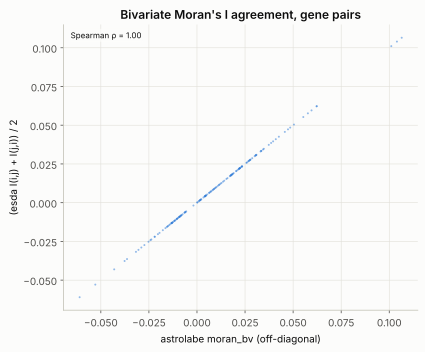

In [5]:
iu = np.triu_indices(n_genes, k=1)  # off-diagonal only -- see note above on the diagonal
astro_vals = corr_astro[iu]
ref_vals = corr_ref[iu]

r = np.corrcoef(astro_vals, ref_vals)[0, 1]
max_abs_diff = float(np.abs(astro_vals - ref_vals).max())
print(f"Pearson r = {r:.8f}, max |astrolabe - symmetrized esda| = {max_abs_diff:.2e}")
print(f"Runtime: astrolabe {t_astro_s:.4f}s vs esda-looped {t_ref_s:.4f}s "
      f"({max(t_astro_s, t_ref_s) / min(t_astro_s, t_ref_s):.1f}x astrolabe {'faster' if t_astro_s < t_ref_s else 'slower'})")

panel = ab.pl.scatter(
    adata, x=astro_vals, y=ref_vals, annotate_corr=True,
    xlabel="astrolabe moran_bv (off-diagonal)", ylabel="(esda I(i,j) + I(j,i)) / 2",
    title="Bivariate Moran's I agreement, gene pairs",
)
panel.show()


## Interpretation

Once esda's raw, asymmetric `I(i,j)` is symmetrized the same way astrolabe does, a near-zero max absolute difference confirms both the ddof cancellation and the symmetrization convention are correct. Skipping the symmetrization step would make the correlation drop sharply - that's a convention mismatch, not a bug. If a real gap ever appears after symmetrizing, check whether the two weight objects (astrolabe's `W_norm` vs. esda's row-standardized `w`) are built from the same `obsp` connectivity.